# Assignment 2: Exploratory Analysis and Data Cleaning

## EDA of Refah Iranian Dataset

## Author: Mohammad Mehdi Zare, Mohammad Ali Olama

# Abstract

This report presents the Exploratory Data Analysis (EDA) of the **Refah Iranian** dataset. The primary objective of this project is to examine, analyze, and identify patterns, relationships, and key insights within the data. Through this process, various features and variables are explored, data quality is assessed, and any inconsistencies or anomalies are identified.

# Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install arabic_reshaper

In [ ]:
!pip install python-bidi

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
from matplotlib.category import UnitData

# We need these libraries for Farsi writting
import arabic_reshaper
import bidi.algorithm

wr.filterwarnings('ignore')

# Display all columns in DataFrame format
pd.set_option('display.max_columns', None)

# Read dataset

In [ ]:
df_org=pd.read_csv("/content/drive/MyDrive/TEIAS/ADS/HW2/nemone_2_darsadi_1402.csv")
df_org.head()

In [ ]:
# df=pd.read_csv("nemone_2_darsadi_1402.csv")
# df.head()

In [ ]:
df = df_org

As you can see, the dataset is contains many cells that are 'NaN'. It seems that this data set is not clean, thus, a lot of work should be done!

## Data Structure
In this part, we explain the structure of the dataset by using the pandas function.
* Column names and type
* Number of unique values in each column
* Percentage of null value in each columns

First let's have a look at data type of each cell:

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1697816 entries, 0 to 1697815
Data columns (total 48 columns):
 #   Column                               Dtype  
---  ------                               -----  
 0   id                                   int64  
 1   Parent_Id                            int64  
 2   GenderId                             int64  
 3   Age                                  float64
 4   ISBimarKhas                          float64
 5   IsMalool                             float64
 6   Malool_shedat                        float64
 7   Dashboard_postalcode7Digits          float64
 8   isurban                              float64
 9   SabteAhval_provincename              object 
 10  SabteAhval_countyname                object 
 11  Has_SoeTaghzie                       float64
 12  IsBehzisti_AfzayeshMostamari         float64
 13  IsKomite_AfzayeshMostamari           float64
 14  IsKomite_AfzayeshMostamariSayer      float64
 15  TripCountAirPilgrimage_95to99   

In [ ]:
df.describe()

,id,Parent_Id,GenderId,Age,ISBimarKhas,IsMalool,Malool_shedat,Dashboard_postalcode7Digits,isurban,Has_SoeTaghzie,IsBehzisti_AfzayeshMostamari,IsKomite_AfzayeshMostamari,IsKomite_AfzayeshMostamariSayer,TripCountAirPilgrimage_95to99,TripCountAirNonPilgrimage_95to99,TripCountNonAirPilgrimage_95to99,TripCountNonAirNonPilgrimage_95to99,Has_Saham_Edalat,Decile,Percentile,HasMojavezSenfi,ISKarmanddolat_1402,IsRetired_Asli,IsRetired_Tabaie,is_bime_darman,IsBimePardaz,MandehAval_1399,MandehAkhar_1399,CardPerMonth_1399,Variz_1400,MandehAval_1400,MandehAkhar_1400,CardPerMonth_1400,CardPerMonth_1398,CardPerMonth_1401,CardPerMonth_1402,CardBeCardPerMonth_1401,CardBeCardPerMonth_1402,SatnaPerMonth_1401,SatnaPerMonth_1402,PayaPerMonth_1401,PayaPerMonth_1402,CarsPrice,CarsCount,Bourse_NetPortfoValue,Daramad
count,1.697816e+06,1.697816e+06,1.697816e+06,1.696590e+06,13331.0,28419.0,27454.000000,1.657326e+06,1.657326e+06,140735.000000,38108.0,87929.0,11049.0,200071.000000,200071.000000,200071.000000,200071.000000,883527.0,1.697816e+06,1.697816e+06,1.697816e+06,1.697816e+06,98681.0,8026.0,1380451.0,317529.0,1.373335e+06,1.373335e+06,1.697816e+06,1.365934e+06,1.365934e+06,1.365934e+06,1.697816e+06,1.697816e+06,1.697816e+06,1.697816e+06,1.697816e+06,1.697816e+06,1.697816e+06,1.697816e+06,1.697816e+06,1.697816e+06,4.080750e+05,408075.000000,1.659997e+06,4.548810e+05
mean,4.361329e+11,4.332060e+11,1.494946e+00,3.408394e+01,1.0,1.0,2.278138,6.050426e+06,6.981879e-01,0.020208,1.0,1.0,1.0,0.089608,0.844090,0.346477,0.346477,1.0,5.508390e+00,5.057429e+01,2.931825e-02,3.982057e-02,1.0,1.0,1.0,1.0,1.847678e+08,3.103018e+08,4.357439e+07,3.583436e+09,2.100670e+08,3.195677e+08,5.670514e+07,2.848295e+07,8.563050e+07,1.046236e+08,1.494714e+08,1.136126e+08,1.442665e+08,1.259986e+08,1.020751e+08,7.670755e+07,4.319120e+09,1.231230,9.303407e+07,9.665717e+07
std,2.524222e+11,2.500585e+11,4.999746e-01,2.031489e+01,0.0,0.0,0.905472,2.451701e+06,4.590443e-01,0.140712,0.0,0.0,0.0,0.690080,2.904279,1.942321,1.942321,0.0,2.877237e+00,2.892483e+01,1.686971e-01,1.955375e-01,0.0,0.0,0.0,0.0,1.393042e+09,2.238381e+09,1.719363e+08,1.118741e+10,1.562919e+09,2.181309e+09,1.450931e+08,1.339742e+08,2.294091e+08,3.204369e+08,3.431784e+08,2.607396e+08,1.073602e+09,1.303924e+09,4.966068e+08,4.365567e+08,9.629254e+09,0.649734,6.323638e+09,6.975295e+07
min,2.743800e+04,2.599360e+05,1.000000e+00,0.000000e+00,1.0,1.0,1.000000,1.111100e+06,0.000000e+00,0.000000,1.0,1.0,1.0,0.000000,0.000000,0.000000,0.000000,1.0,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,1.0,1.0,1.0,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,0.000000e+00,0.000000e+00
25%,2.178905e+11,2.167209e+11,1.000000e+00,1.700000e+01,1.0,1.0,2.000000,4.341784e+06,0.000000e+00,0.000000,1.0,1.0,1.0,0.000000,0.000000,0.000000,0.000000,1.0,3.000000e+00,2.500000e+01,0.000000e+00,0.000000e+00,1.0,1.0,1.0,1.0,2.500000e+06,2.500000e+06,0.000000e+00,5.250000e+07,2.500000e+06,2.500000e+06,0.000000e+00,0.000000e+00,2.306730e+05,7.025400e+04,1.831730e+05,5.920000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.171194e+09,1.000000,0.000000e+00,5.485227e+07
50%,4.355807e+11,4.330983e+11,1.000000e+00,3.400000e+01,1.0,1.0,2.000000,6.414943e+06,1.000000e+00,0.000000,1.0,1.0,1.0,0.000000,0.000000,0.000000,0.000000,1.0,6.000000e+00,5.100000e+01,0.000000e+00,0.000000e+00,1.0,1.0,1.0,1.0,7.500000e+06,1.750000e+07,4.771200e+06,5.500000e+08,1.250000e+07,1.750000e+07,9.646261e+06,2.376767e+06,2.122736e+07,3.142441e+07,3.761553e+07,3.583223e+07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.250518e+09,1.000000,0.000000e+00,7.712800e+07
75%,6.538524e+11,6.498149e+11,2.000000e+00,4.800000e+01,1.0,1.0,3.000000,7.918655e+06,1.000000e+00,0.000000,1.0,1.0,1.0,0.000000,1.000000,0.000000,0.000000,1.0,8.000000e+00,7.600000e+01,0.000000e+00,0.000000e+00,1

## Count number of unique values in each column

In [ ]:
# Count number of distinct elements
df.nunique(axis=0)

,0
id,1697816
Parent_Id,595688
GenderId,2
Age,100
ISBimarKhas,1
IsMalool,1
Malool_shedat,4
Dashboard_postalcode7Digits,196389
isurban,2
SabteAhval_provincename,31


## Count unique values in some categorical columns.

it seems that many columns are actually categorical values. let's have a look at some of them here:

In [ ]:
df['Malool_shedat'].value_counts()

,count
Malool_shedat,
3.0,10311
2.0,8645
1.0,6557
4.0,1941


In [ ]:
df['SabteAhval_provincename'].value_counts()

,count
SabteAhval_provincename,
تهران,229192
خراسان رضوی,124688
خوزستان,100123
اصفهان,97193
فارس,95705
آذربایجان شرقی,78225
آذربایجان غربی,66685
مازندران,65883
سیستان وبلوچستان,59318


In [ ]:
df['Age'].value_counts()

,count
Age,
37.0,37241
39.0,36092
38.0,35660
40.0,34456
34.0,34296
...,...
95.0,324
96.0,297
97.0,225






We don't know the values is 'GenderId'. It has 1 and 2. so we perform another analysis to find out. we search for the people whose 'parent_id' is equal to its 'id. (people who are head of the household). We assume that in a normal population sample, most heads of the household are men. so by performing the following analysis, we find out that '1' is equal to 'Male' and '2' is the same as 'female'.

In [ ]:
(df[df['Parent_Id'] == df['id']])['GenderId'].value_counts()

,count
GenderId,
1,462770
2,132918


Also let's plot a pie chart of gender distribution :

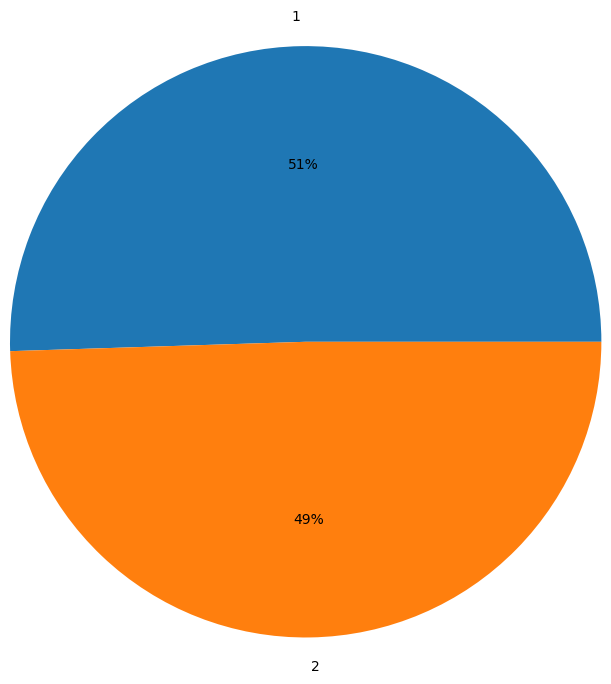

In [ ]:
df['GenderId'].value_counts()[0:2].plot.pie(autopct='%1.0f%%',radius=2,ylabel='')
# plt.title('Transmission Type', y=1.5,fontsize=20)
plt.show()

It seems that we don't have gender bias in our dataset.

## Calculate null ratio in each column

In [ ]:
df.isnull().sum()

,0
id,0
Parent_Id,0
GenderId,0
Age,1226
ISBimarKhas,1684485
IsMalool,1669397
Malool_shedat,1670362
Dashboard_postalcode7Digits,40490
isurban,40490
SabteAhval_provincename,141430


In [ ]:
# Percentage of null value of each column
(df.isnull().sum()/(len(df)))*100

,0
id,0.000000
Parent_Id,0.000000
GenderId,0.000000
Age,0.072210
ISBimarKhas,99.214815
IsMalool,98.326144
Malool_shedat,98.382981
Dashboard_postalcode7Digits,2.384829
isurban,2.384829
SabteAhval_provincename,8.330114


We can also add another column, 'age_cat', where we convert 'Age' to some categories: Child, Teen, Young, Adult, Elder.

In [ ]:
# also let's categorize age of people:

def categorize_age(age):
    if (age < 10):
        return 'Child'
    elif (age < 18):
        return 'Teen'
    elif (age < 30):
        return 'Young'
    elif (age < 50):
        return 'Adult'
    else :
        return 'Elder'

df['age_cat'] = df['Age'].apply(categorize_age).astype('str')
df['age_cat']

,age_cat
0,Child
1,Adult
2,Adult
3,Elder
4,Adult
...,...
1697811,Teen
1697812,Adult
1697813,Adult
1697814,Elder


It's worth mentioning that not all the 'NaN' values in the dataset means that they are not recorded or unavailable.

Please take a look at the 'ISBimarKhas' column. It has a null ratio of above 99%. But we can expect the 'NaN' in this column to be the same as '0' (or false), meaning that person has no special illness.

we will assume the above point is true for other categorical features as well.

Now we perform another analysis. we calculate mean of 3 columns based on 'Decile'. As it can be seen, people in higher Deciles have more 'Datamad', have more expensive cars, and have more money saved at the end of year 1400. All these columns have an ascending behavior.

In [ ]:
df.groupby(['Decile'])[['Daramad' , 'CarsPrice' , 'MandehAkhar_1400']].mean()

,Daramad,CarsPrice,MandehAkhar_1400
Decile,,,
1,4.091247e+07,4.781583e+08,4.611230e+07
2,6.493446e+07,9.200523e+08,6.381161e+07
3,7.470134e+07,1.007306e+09,6.851477e+07
4,8.162276e+07,1.391634e+09,8.458509e+07
5,8.757120e+07,1.803640e+09,1.179762e+08
6,9.359260e+07,2.220631e+09,1.858311e+08
7,9.947485e+07,2.652531e+09,3.309443e+08
8,1.075751e+08,3.271689e+09,3.889053e+08
9,1.147784e+08,4.627587e+09,5.150673e+08


# Handling Missing and Incorrect Data
In this part, we try to clean data and prepare for EDA and other analysis.

First let's talk about duplicate values :

In [ ]:
df_new = df.drop_duplicates(inplace=False , ignore_index=True)


print(f'number of duplicate rows: {len(df) - len(df_new)}' )

number of duplicate rows: 0


the dataset contains no duplicate entries.

Next, the following columns are considered as 'object' . but they are actually String categories. so let's convert them :

In [ ]:
df["SabteAhval_provincename"]=df["SabteAhval_provincename"].astype(str)
df["SabteAhval_provincename"] = df["SabteAhval_provincename"].str.strip()

Then, to check if this column contains any inconsistencies, we perform the following check :

In [ ]:
provinces = df["SabteAhval_provincename"].unique()

provinces.sort()
provinces

array(['nan', 'آذربایجان شرقی', 'آذربایجان غربی', 'اردبیل', 'اصفهان',
       'البرز', 'ایلام', 'بوشهر', 'تهران', 'خراسان جنوبی', 'خراسان رضوی',
       'خراسان شمالی', 'خوزستان', 'زنجان', 'سمنان', 'سیستان وبلوچستان',
       'فارس', 'قزوین', 'قم', 'لرستان', 'مازندران', 'مرکزی', 'هرمزگان',
       'همدان', 'چهارمحال وبختیاری', 'کردستان', 'کرمان', 'کرمانشاه',
       'کهگیلویه وبویراحمد', 'گلستان', 'گیلان', 'یزد'], dtype=object)

It seems that these values contain no inconsistencies.for example with don't have 'آذربایجان' and 'اذربایجان' .

we should check this for several columns, but for the sake of simplicity, we just perform it on 1 column.



## Deleting some irrelevant columns

Suppose our task is to estimate 'Daramad'. (or classify new instances with their 'Decile'). If we explore the dataset columns, we understand that some of the columns are really irrelevant to our task. for example:

In [ ]:
# we think these features are not required.
del df["Dashboard_postalcode7Digits"]

## Fill NA value

According to our problem, we decided to fill NA value with 0 or  the median value of each columns.
Note: data has a lot of NA values. Therefore, dropping rows is not a good solution to handle NA values.

### How columns filled:
* Columns with boolean value and those count somthing(f.g.TripCountNonAirNonPilgrimage_95to99) fill with zero. NaN values for boolean columns can be interpreted as 'False' (for example, if 'ISBimarKhas' is NaN, can be interpreted that he/she does not have any special illness), and NaN values in some integer columns can be interpreted as '0'.(for instance, if 'TripCountNonAirNonPilgrimage_95to99' is NaN, we can assume that person didn't have any trip in those years and thus, nothing is recorded for his/her trips.)
* Columns that represent an individual's assets, such as account balance, were filled with the median. It's obvious that putting '0' is not good. Moreover, if we replace those values with the mean of that column, it might cause some issues, as mean is very sensitive to outliers. So we decided to fill those NaN with the 'median' of that column.


*   One exception is 'Age'. We decided to fill NaN with 'mean' of this column. (We took a look at the dataset and the 'Age' column didn't have outliers (the range of values was 0 to 100) )



In [ ]:
from scipy import stats
cols = df.columns.tolist()
cols = cols[27:44]



# 01
df["Age"].fillna(df["Age"].mean(), inplace=True)

# 02
df.fillna({'MandehAval_1399':df["MandehAval_1399"].median(), 'MandehAkhar_1399':df["MandehAkhar_1399"].median(), 'Variz_1400':df["Variz_1400"].median(), 'MandehAval_1400':df["MandehAval_1400"].median(),'MandehAkhar_1400':df["MandehAkhar_1400"].median()}, inplace=True)

for c in cols:
  df[c].replace(to_replace=0 , value = df[c].median())


#03
columns=["ISBimarKhas","IsMalool","Malool_shedat","Has_SoeTaghzie","IsBehzisti_AfzayeshMostamari","IsKomite_AfzayeshMostamari","IsKomite_AfzayeshMostamariSayer","TripCountAirPilgrimage_95to99","TripCountAirNonPilgrimage_95to99","TripCountNonAirNonPilgrimage_95to99","TripCountNonAirNonPilgrimage_95to99","TripCountNonAirPilgrimage_95to99","Has_Saham_Edalat","IsRetired_Asli","IsRetired_Tabaie","is_bime_darman","IsBimePardaz","CarsCount","CarsPrice","Bourse_NetPortfoValue","Daramad"]
for col in columns:
    df[col].fillna(0 , inplace=True)

Also, to check whether we don't have any invalid values( e.g. negative values in numerical columns) we do the following check:

In [ ]:
np.where(df[cols] < 0)

(array([], dtype=int64), array([], dtype=int64))

It was obvious from df.describe().

----------------------

# Exploratory Data Analysis
In this part, we draw some plots to find patterns and get more familiar with data sets and columns. So we can understand which columns should be used in estimating household assets.

# Categorize columns

again, let's have a look at our dataframe types:



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1697816 entries, 0 to 1697815
Data columns (total 48 columns):
 #   Column                               Dtype  
---  ------                               -----  
 0   id                                   int64  
 1   Parent_Id                            int64  
 2   GenderId                             int64  
 3   Age                                  float64
 4   ISBimarKhas                          float64
 5   IsMalool                             float64
 6   Malool_shedat                        float64
 7   isurban                              float64
 8   SabteAhval_provincename              object 
 9   SabteAhval_countyname                object 
 10  Has_SoeTaghzie                       float64
 11  IsBehzisti_AfzayeshMostamari         float64
 12  IsKomite_AfzayeshMostamari           float64
 13  IsKomite_AfzayeshMostamariSayer      float64
 14  TripCountAirPilgrimage_95to99        float64
 15  TripCountAirNonPilgrimage_95to99

In [ ]:
df.nunique(axis=0)

,0
id,1697816
Parent_Id,595688
GenderId,2
Age,101
ISBimarKhas,2
IsMalool,2
Malool_shedat,5
isurban,2
SabteAhval_provincename,32
SabteAhval_countyname,465


In [ ]:
to_categorical_columns = ['Malool_shedat','SabteAhval_provincename','SabteAhval_countyname' , 'age_cat']
for column in to_categorical_columns:
  df[column] = df[column].astype('category').cat.codes

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1697816 entries, 0 to 1697815
Data columns (total 48 columns):
 #   Column                               Dtype  
---  ------                               -----  
 0   id                                   int64  
 1   Parent_Id                            int64  
 2   GenderId                             int64  
 3   Age                                  float64
 4   ISBimarKhas                          float64
 5   IsMalool                             float64
 6   Malool_shedat                        int8   
 7   isurban                              float64
 8   SabteAhval_provincename              int8   
 9   SabteAhval_countyname                int16  
 10  Has_SoeTaghzie                       float64
 11  IsBehzisti_AfzayeshMostamari         float64
 12  IsKomite_AfzayeshMostamari           float64
 13  IsKomite_AfzayeshMostamariSayer      float64
 14  TripCountAirPilgrimage_95to99        float64
 15  TripCountAirNonPilgrimage_95to99

# Correlation analysis

In [ ]:
corr = df.corr()
corr.style.background_gradient(cmap='coolwarm')

,id,Parent_Id,GenderId,Age,ISBimarKhas,IsMalool,Malool_shedat,isurban,SabteAhval_provincename,SabteAhval_countyname,Has_SoeTaghzie,IsBehzisti_AfzayeshMostamari,IsKomite_AfzayeshMostamari,IsKomite_AfzayeshMostamariSayer,TripCountAirPilgrimage_95to99,TripCountAirNonPilgrimage_95to99,TripCountNonAirPilgrimage_95to99,TripCountNonAirNonPilgrimage_95to99,Has_Saham_Edalat,Decile,Percentile,HasMojavezSenfi,ISKarmanddolat_1402,IsRetired_Asli,IsRetired_Tabaie,is_bime_darman,IsBimePardaz,MandehAval_1399,MandehAkhar_1399,CardPerMonth_1399,Variz_1400,MandehAval_1400,MandehAkhar_1400,CardPerMonth_1400,CardPerMonth_1398,CardPerMonth_1401,CardPerMonth_1402,CardBeCardPerMonth_1401,CardBeCardPerMonth_1402,SatnaPerMonth_1401,SatnaPerMonth_1402,PayaPerMonth_1401,PayaPerMonth_1402,CarsPrice,CarsCount,Bourse_NetPortfoValue,Daramad,age_cat
id,1.000000,0.347181,-0.000980,-0.018451,-0.001948,-0.000702,-0.000628,-0.000812,-0.008719,-0.009018,0.009888,0.000494,-0.001719,-0.000546,0.000074,-0.001988,-0.000769,-0.000769,-0.012466,-0.001306,-0.001232,-0.003184,-0.003340,-0.002314,0.000087,-0.005205,-0.006895,-0.002713,-0.001921,-0.004150,-0.003785,-0.002176,-0.001346,-0.004581,-0.003746,-0.005024,-0.004893,-0.005565,-0.005801,-0.002412,-0.001520,-0.003406,-0.002234,-0.002486,-0.005671,-0.000216,-0.007021,-0.004247
Parent_Id,0.347181,1.000000,0.000182,0.001179,-0.000385,-0.000257,-0.000424,-0.001114,-0.000012,-0.000910,0.000036,0.000042,0.000047,-0.001979,0.000034,-0.000513,0.000339,0.000339,0.000586,-0.001565,-0.001430,-0.000985,-0.001653,0.000604,0.000639,-0.000265,-0.001198,-0.001286,-0.000851,-0.001269,-0.001234,-0.001075,-0.000976,-0.000509,-0.001297,-0.000800,-0.000707,-0.000593,-0.000372,-0.000886,-0.001245,-0.000838,-0.000109,-0.000751,-0.000839,-0.000289,-0.001969,-0.000177
GenderId,-0.000980,0.000182,1.000000,0.019063,0.014787,-0.032046,-0.027374,0.001134,0.003128,0.001736,-0.000997,0.024078,0.073005,-0.003526,-0.002885,-0.006915,-0.021734,-0.021734,0.045824,-0.053376,-0.054325,-0.090585,-0.033517,-0.149360,0.046415,0.056636,-0.259083,-0.034329,-0.033131,-0.143054,-0.151478,-0.038270,-0.037201,-0.201115,-0.124101,-0.174960,-0.142548,-0.184325,-0.167944,-0.071811,-0.052419,-0.120513,-0.092022,-0.067155,-0.197020,-0.007424,-0.261865,0.000175
Age,-0.018451,0.001179,0.019063,1.000000,0.086247,0.021979,0.019108,0.074861,0.070219,0.075771,-0.063786,-0.011865,0.125723,0.006082,0.030006,0.039678,0.020466,0.020466,0.393619,0.002137,-0.000260,0.095893,0.101849,0.369572,0.077702,0.055063,0.177232,0.101787,0.108100,0.117029,0.131464,0.098377,0.105409,0.171679,0.108716,0.158843,0.133184,0.168090,0.160772,0.064998,0.044661,0.083744,0.063827,0.096752,0.231091,0.010594,0.280303,-0.173396
ISBimarKhas,-0.001948,-0.000385,0.014787,0.086247,1.000000,0.019031,0.017223,0.014868,0.003402,0.003700,-0.003481,0.006477,0.009895,-0.000478,0.004900,0.001504,0.000520,0.000520,0.030344,-0.010783,-0.010733,0.004476,0.080341,0.046951,0.009338,0.001385,0.027721,0.012607,0.013659,0.005119,0.005632,0.009792,0.012367,0.006461,0.005250,0.005160,0.005007,0.003135,0.003462,0.002190,0.001537,0.003986,0.004080,0.007063,0.011685,0.001030,0.038697,-0.000964
IsMalool,-0.000702,-0.000257,-0.032046,0.021979,0.019031,1.000000,0.912091,-0.019634,0.019604,0.012272,0.000381,0.252856,-0.005486,-0.001653,-0.003426,-0.009950,-0.005109,-0.005109,0.051574,-0.096161,-0.096370,-0.000332,-0.012178,0.000828,0.005399,0.029880,-0.012186,-0.007949,-0.007955,-0.016553,-0.021994,-0.008248,-0.008200,-0.023295,-0.014097,-0.021668,-0.019114,-0.025694,-0.024071,-0.012101,-0.008909,-0.017019,-0.013121,-0.017833,-0.029084,-0.001246,-0.021660,-0.004034
Malool_shedat,-0.000628,-0.000424,-0.027374,0.019108,0.017223,0.912091,1.000000,-0.016425,0.013946,0.009624,0.000802,0.228751,-0.008862,-0.003029,-0.003089,-0.009114,-0.004933,-0.004933,0.046674,-0.088078,-0.088414,-0.002591,-0.011838,0.001641,0.005807,0.026341,-0.016474,-0.007391,-0.007234,-0.016447,-0.021492,-0.007444,-0.007317,-0.024124,-0.013767,-0.022568,-0.019621,

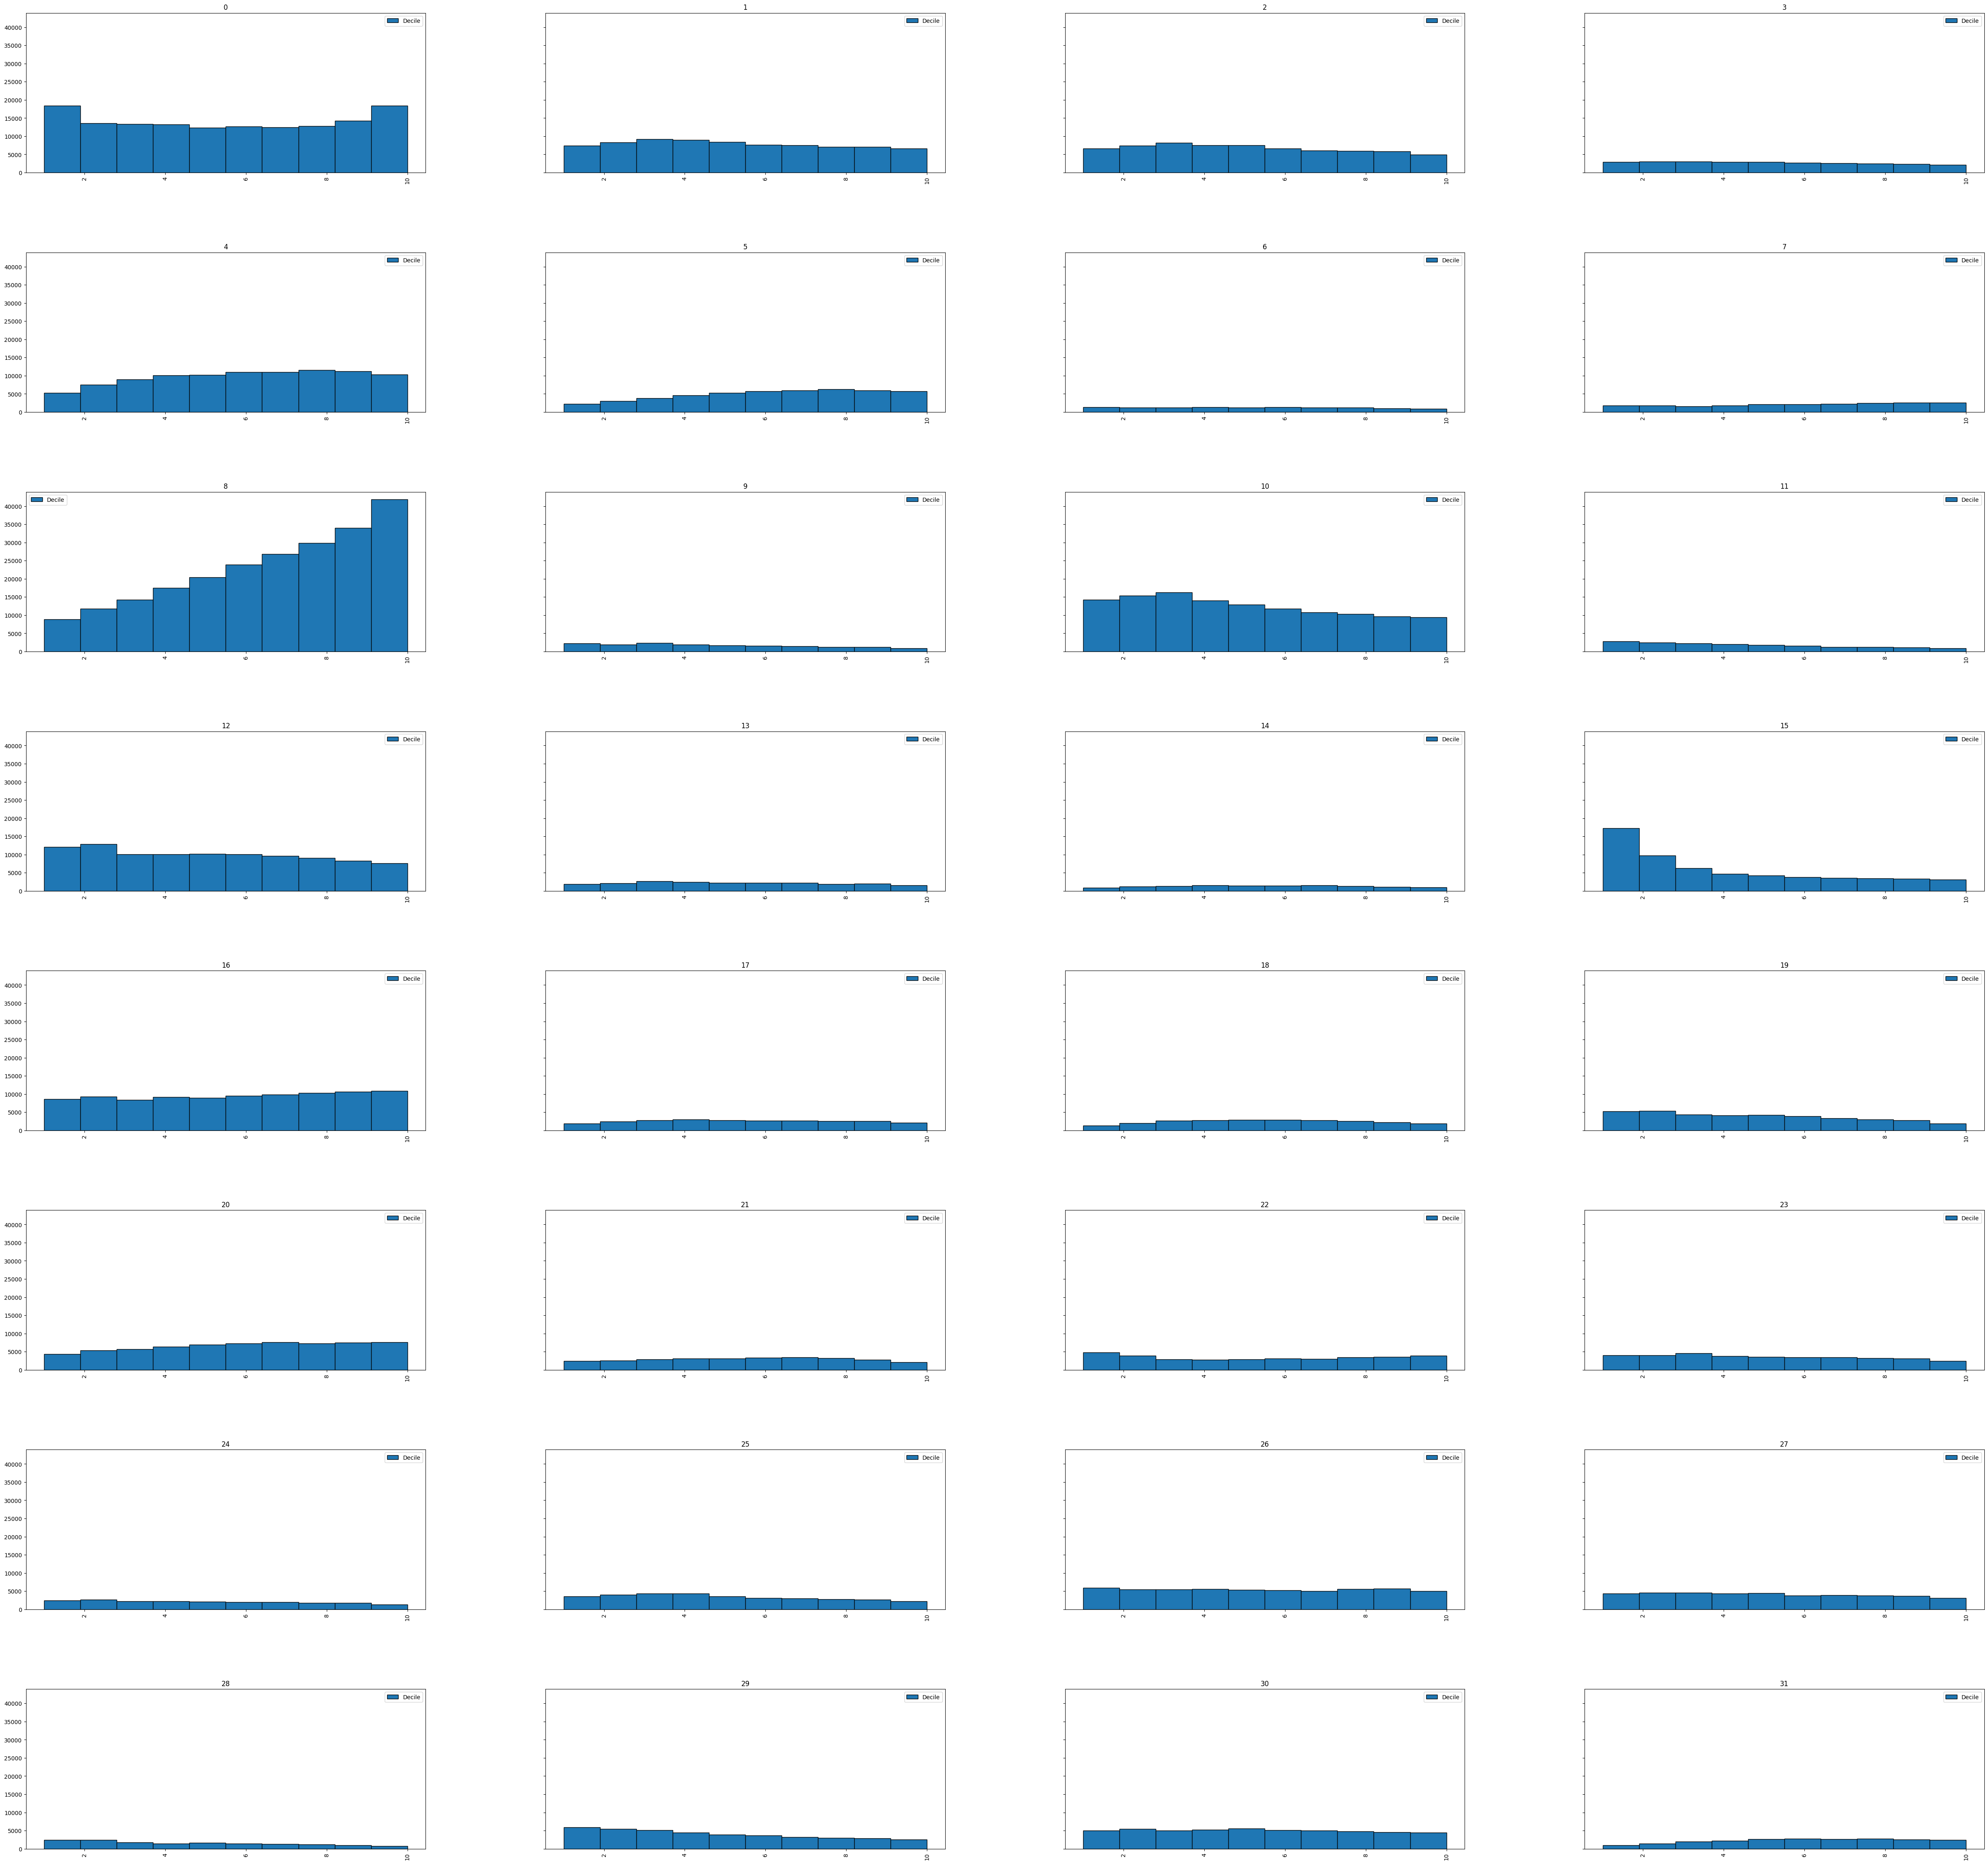

In [ ]:
# To ensure that the horizontal axis in the plot is sorted, we need to convert the percentile type from object to integer.
df['Decile']=df['Decile'].astype(int)

#  The number of observations (or frequency) for each category (percentile) in the histogram based on the province.
axes=df.hist(column="Decile",
            by='SabteAhval_provincename',
            figsize=(60,60),
            layout=(8,4),
            legend=True,
            xlabelsize = 10,
            # sharex=True,
            sharey=True,
            log=False,
            edgecolor='black'
            )



def text_fa(x):
    x = arabic_reshaper.reshape(x)
    x = bidi.algorithm.get_display(x)
    return x

for ax in axes.flatten():
    ax.set_title(text_fa(ax.get_title()))


## Standardization/ Normalization


we investigate the dataset and we conclude that we don't need any normalization, since our most important features, which are financial features, are all in the same scale (million toman). Thus, it is not necessary to normalize this dataset. However, we are fully aware that normalizing columns is an important step in EDA.

According to the charts above, we see that the frequency of different percentiles varies across provinces. Although the population sizes of the provinces differ, the shape of the charts varies between provinces. In some provinces, individuals in higher percentiles make up a larger percentage of the population.

# Distribution of the frequency of registered vehicles by individuals.


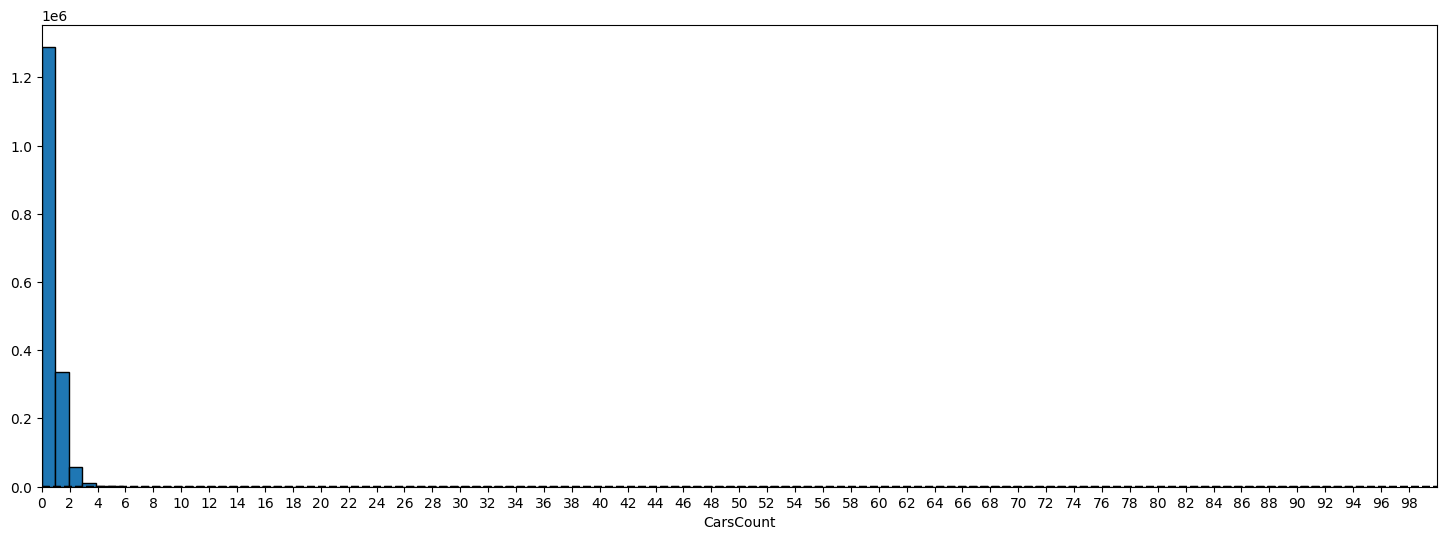

In [ ]:
# Distribution of the frequency of registered vehicles by individuals.
plt.figure(figsize=(18,6))
plt.hist(df["CarsCount"],
         histtype="bar",
         bins=100,
         align='mid',
         edgecolor='black'
        )

plt.hlines(np.arange(5,30,5) ,xmin=0, xmax=100 , linestyles='dashed' ,colors='black')
plt.hlines(1,xmin=0, xmax=100 , linestyles='dashed' ,colors='black')

plt.xlim((1,100))
plt.xlabel("CarsCount" )
plt.xticks(np.arange(0,100,2))

plt.show()

it's normal to think that many people have upto 2 cars, thus the above chart is normal. but let's change to resolution of the chart and trip the 'y' axis to only 100 and 20 respectively :

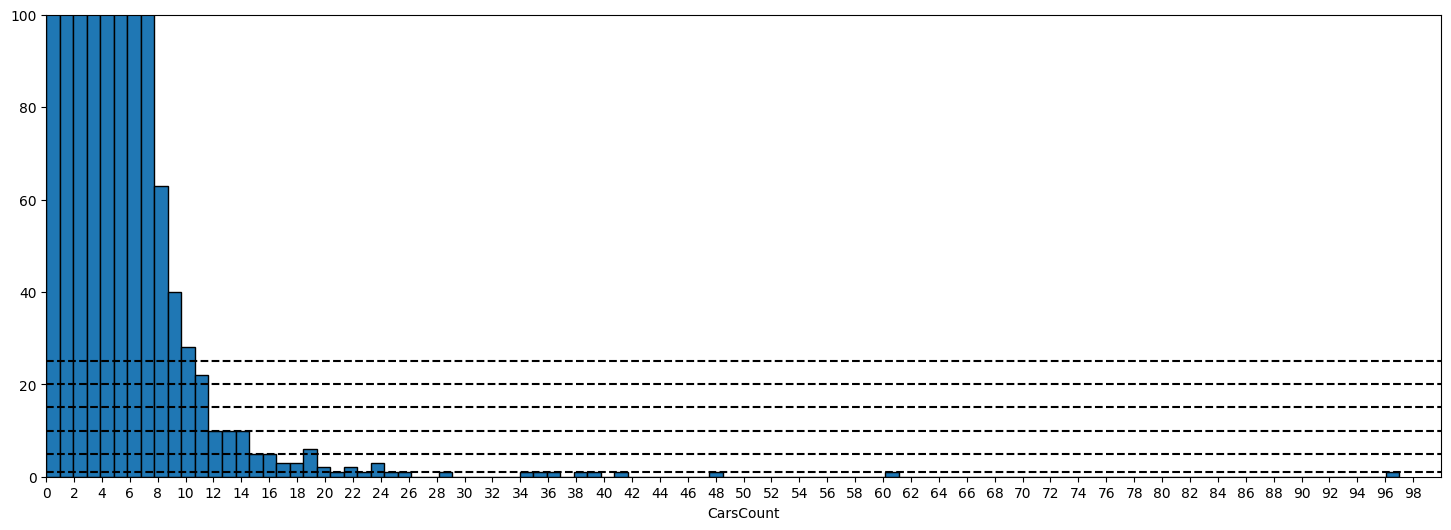

In [ ]:
# Distribution of the frequency of registered vehicles by individuals.
plt.figure(figsize=(18,6))
plt.hist(df["CarsCount"],
         histtype="bar",
         bins=100,
         align='mid',
         edgecolor='black'
        )

plt.hlines(np.arange(5,30,5) ,xmin=0, xmax=100 , linestyles='dashed' ,colors='black')
plt.hlines(1,xmin=0, xmax=100 , linestyles='dashed' ,colors='black')

plt.ylim((0,100))
plt.xlim((1,100))
plt.xlabel("CarsCount" )
plt.xticks(np.arange(0,100,2))

plt.show()

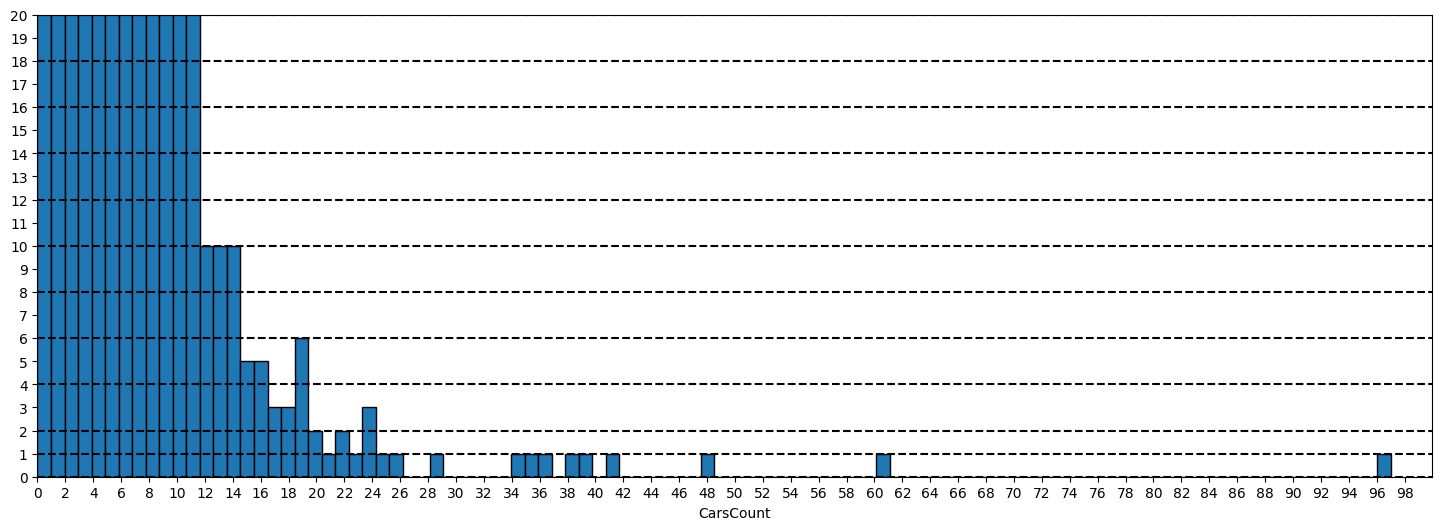

In [ ]:
# Distribution of the frequency of registered vehicles by individuals.
plt.figure(figsize=(18,6))
plt.hist(df["CarsCount"],
         histtype="bar",
         bins=100,
         align='mid',
         edgecolor='black'
        )

plt.hlines(np.arange(0,30,2) ,xmin=0, xmax=100 , linestyles='dashed' ,colors='black')
plt.hlines(1,xmin=0, xmax=100 , linestyles='dashed' ,colors='black')

plt.ylim((0,20))
plt.xlim((1,100))
plt.xlabel("CarsCount" )
plt.xticks(np.arange(0,100,2))
plt.yticks(np.arange(0,21,1))


plt.show()

<Axes: >

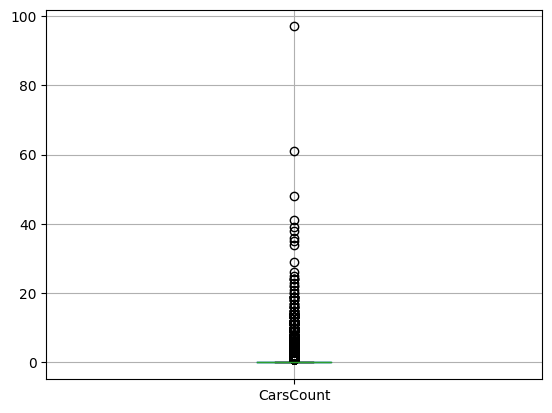

In [ ]:
df.boxplot(column=['CarsCount'])

<Axes: >

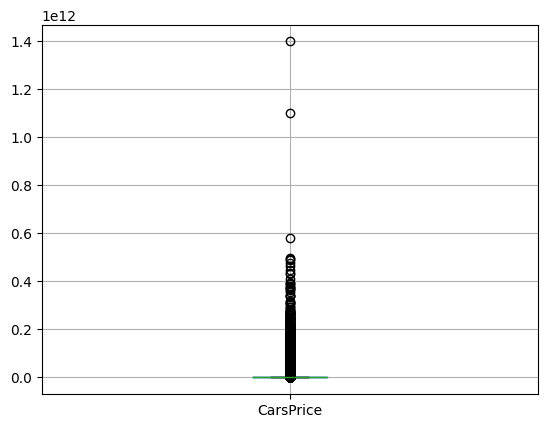

In [ ]:
df.boxplot(column=['CarsPrice'])

Now, we have a better sense for the people who owns more cars.

Now we will examine whether the number of vehicles is related to the individual's percentile.


Text(0.5, 0, 'CarsCount')

<Figure size 640x480 with 0 Axes>

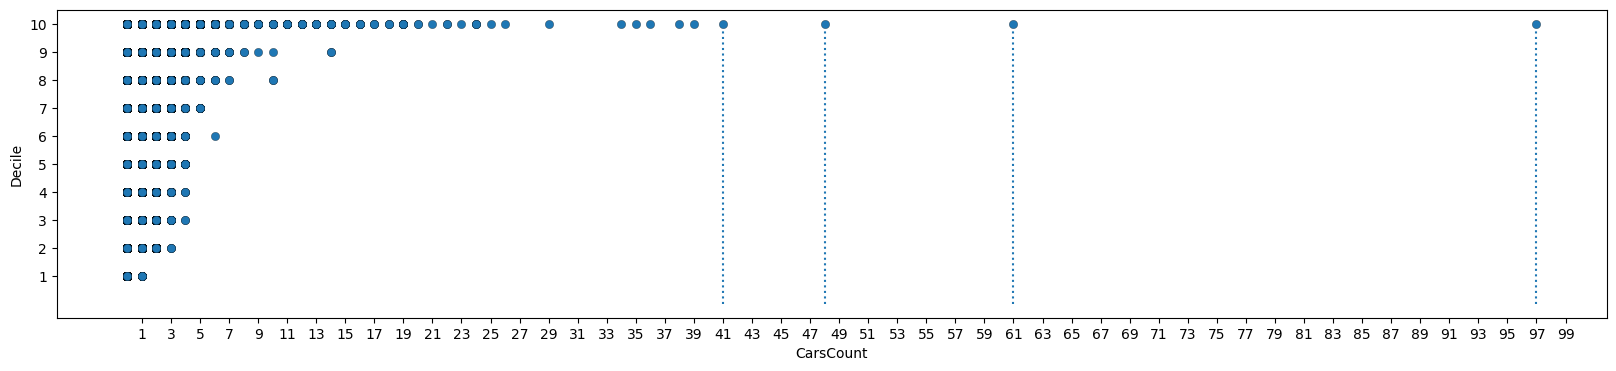

In [ ]:
df['Decile']=df['Decile'].astype(int)

plt.clf()
plt.figure(figsize=(20,4))

plt.scatter(df['CarsCount'],
            df['Decile'],
            edgecolors='black',
            marker='o',
            linewidths=0.2
            )

plt.vlines([41,61,97,48],ymin=0,ymax=10 ,linestyles='dotted')

plt.xticks(np.arange(1,100,2))
plt.yticks(np.arange(1,11,1))

plt.ylabel('Decile')
plt.xlabel('CarsCount')

Text(0.5, 0, 'TripCount')

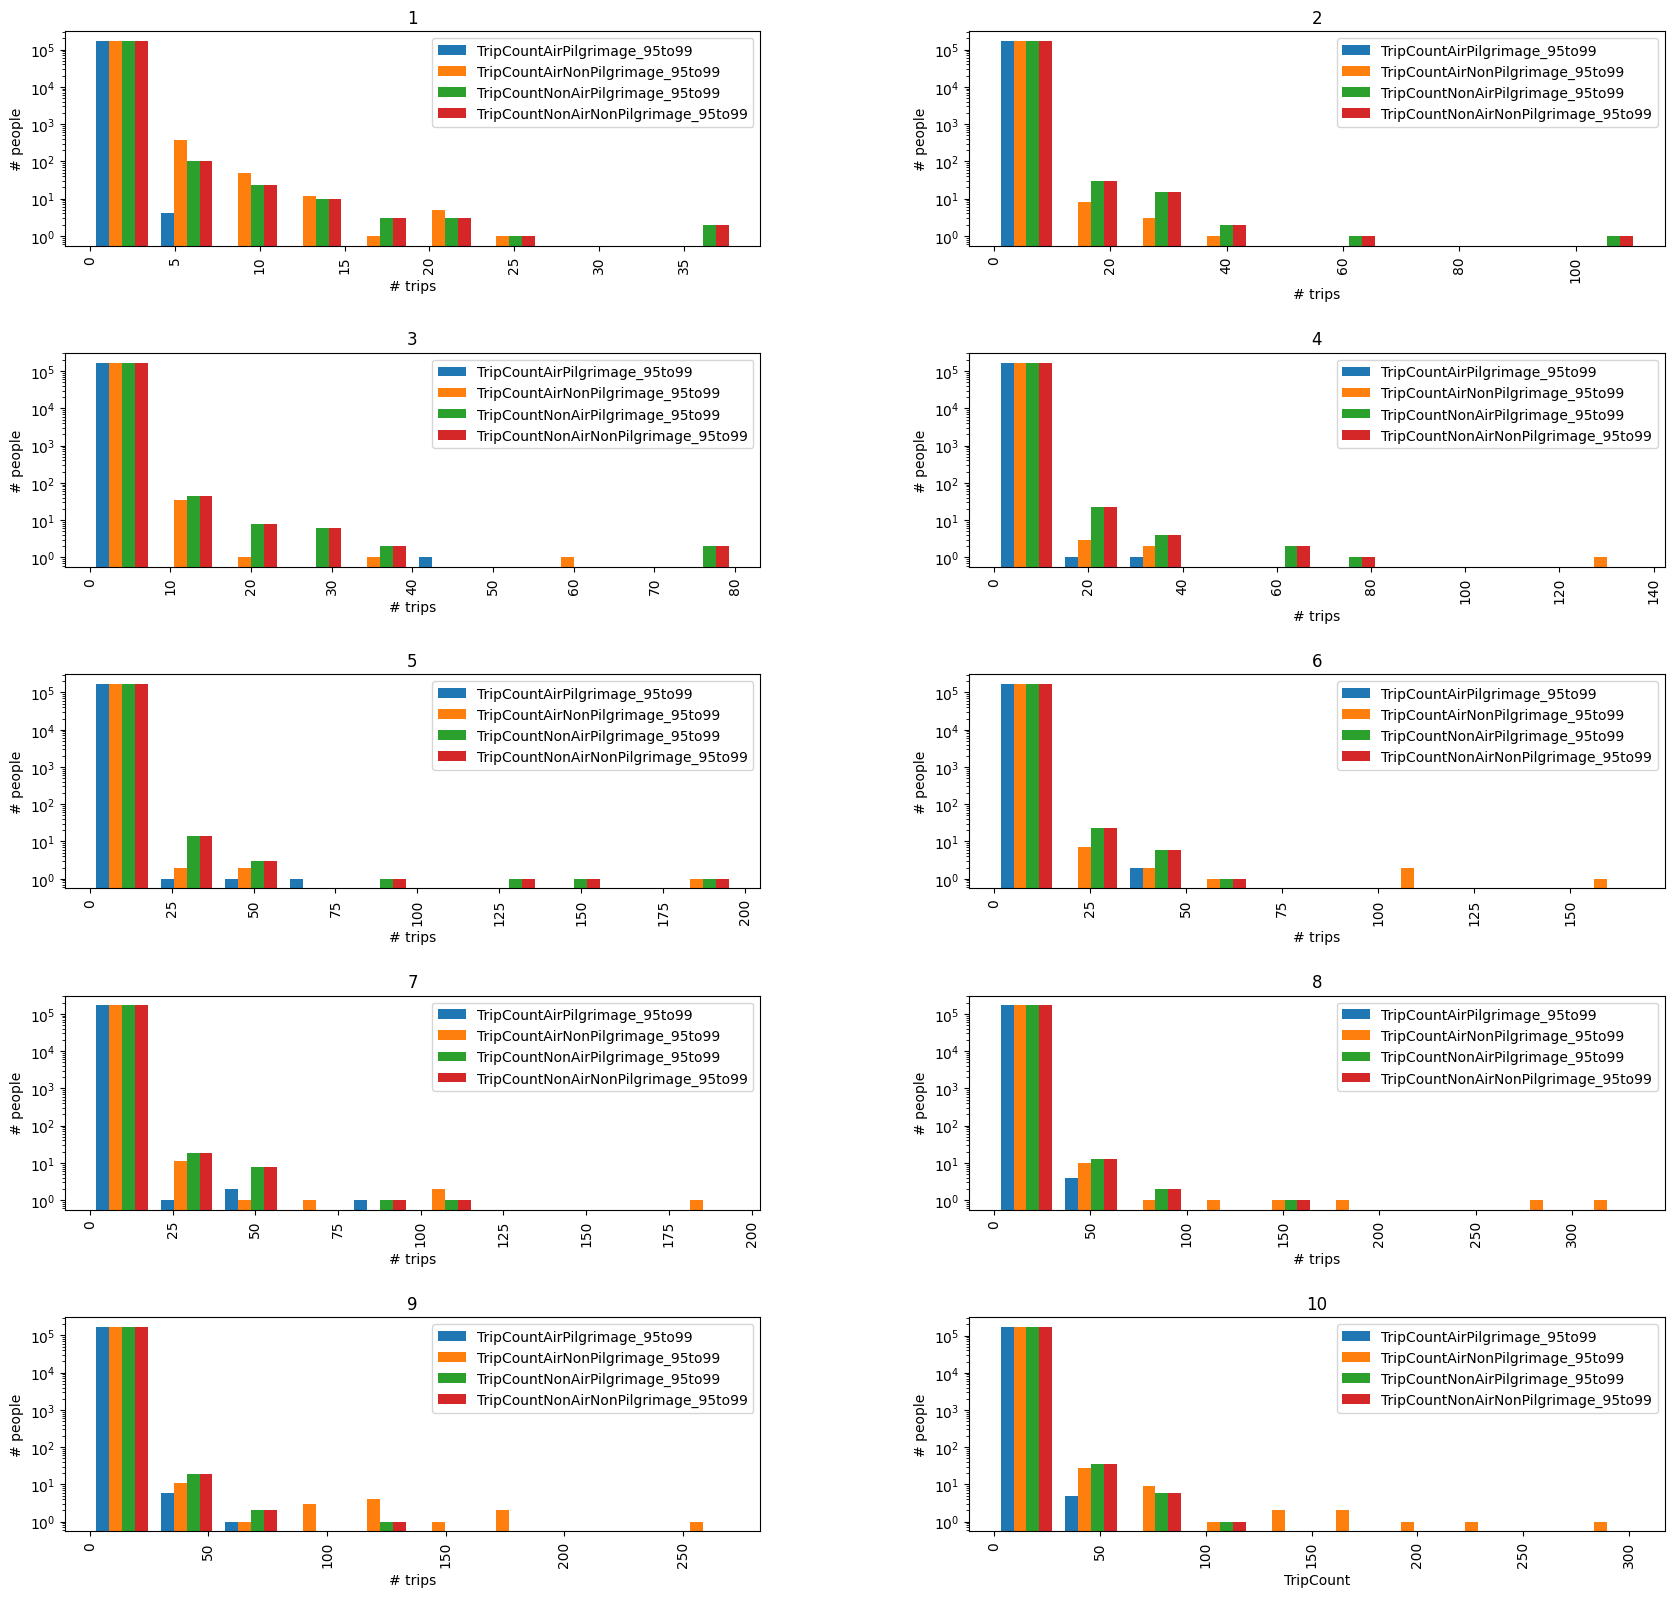

In [ ]:
# Distribution of the frequency of different types of travel (air and non-air) based on percentiles.
# مثلا در دهک یک تعداد لفرادی که دوبار بین سال های 95تا99 سفرهوایی زیارتی داشتند نزدیک 10 نفر است

axis = df.hist(['TripCountAirPilgrimage_95to99','TripCountAirNonPilgrimage_95to99','TripCountNonAirPilgrimage_95to99','TripCountNonAirNonPilgrimage_95to99'],
        by='Decile',
        layout=(5,2),
        legend=True,
        log=True,
        figsize=(20,20)
        )

for ax in axis.flatten():
    ax.set_ylabel("# people")
    ax.set_xlabel("# trips")

plt.xlabel('TripCount')

We observe that individuals in higher percentiles have taken more air travel, while individuals in lower percentiles have taken more ground travel.



Text(0, 0.5, 'CarsPrice')

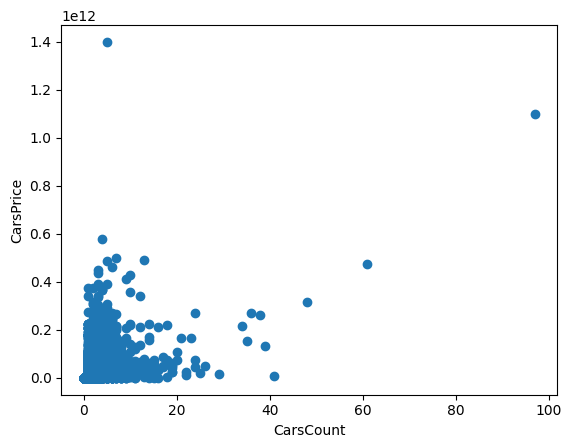

In [ ]:
plt.scatter(df["CarsCount"], df["CarsPrice"] )

plt.xlabel("CarsCount")
plt.ylabel("CarsPrice")

According to the chart above, we infer that the registered vehicle value represents the total value of all the vehicles owned by the individual.



In [ ]:
# Using logarithms to reduce the impact of very large values and data dispersion.

df['MandehAkhar_1399log']=np.log(df["MandehAkhar_1399"]+1)
df['MandehAval_1399log']=np.log(df["MandehAval_1399"]+1)
df['MandehAval_1400log']=np.log(df["MandehAval_1400"]+1)
df['MandehAkhar_1400log']=np.log(df["MandehAkhar_1400"]+1)
df['CardPerMonth_1398log']=np.log(df["CardPerMonth_1398"]+1)
df['PayaPerMonth_1402log']=np.log(df["PayaPerMonth_1402"]+1)
df['Bourse_NetPortfoValuelog']=np.log(df["Bourse_NetPortfoValue"]+1)
df['PayaPerMonth_1401log']=np.log(df["PayaPerMonth_1401"]+1)
df['CardPerMonth_1398log']=np.log(df["CardPerMonth_1398"]+1)
df['CardPerMonth_1399log']=np.log(df["CardPerMonth_1399"]+1)
df['CardPerMonth_1400log']=np.log(df["CardPerMonth_1400"]+1)
df['CardPerMonth_1401log']=np.log(df["CardPerMonth_1401"]+1)
df['CardPerMonth_1402log']=np.log(df["CardPerMonth_1402"]+1)
df['CardBeCardPerMonth_1401log']=np.log(df["CardBeCardPerMonth_1401"]+1)
df['CardBeCardPerMonth_1402log']=np.log(df["CardBeCardPerMonth_1402"]+1)
df['SatnaPerMonth_1401log']=np.log(df["SatnaPerMonth_1401"]+1)
df['SatnaPerMonth_1402log']=np.log(df["SatnaPerMonth_1402"]+1)


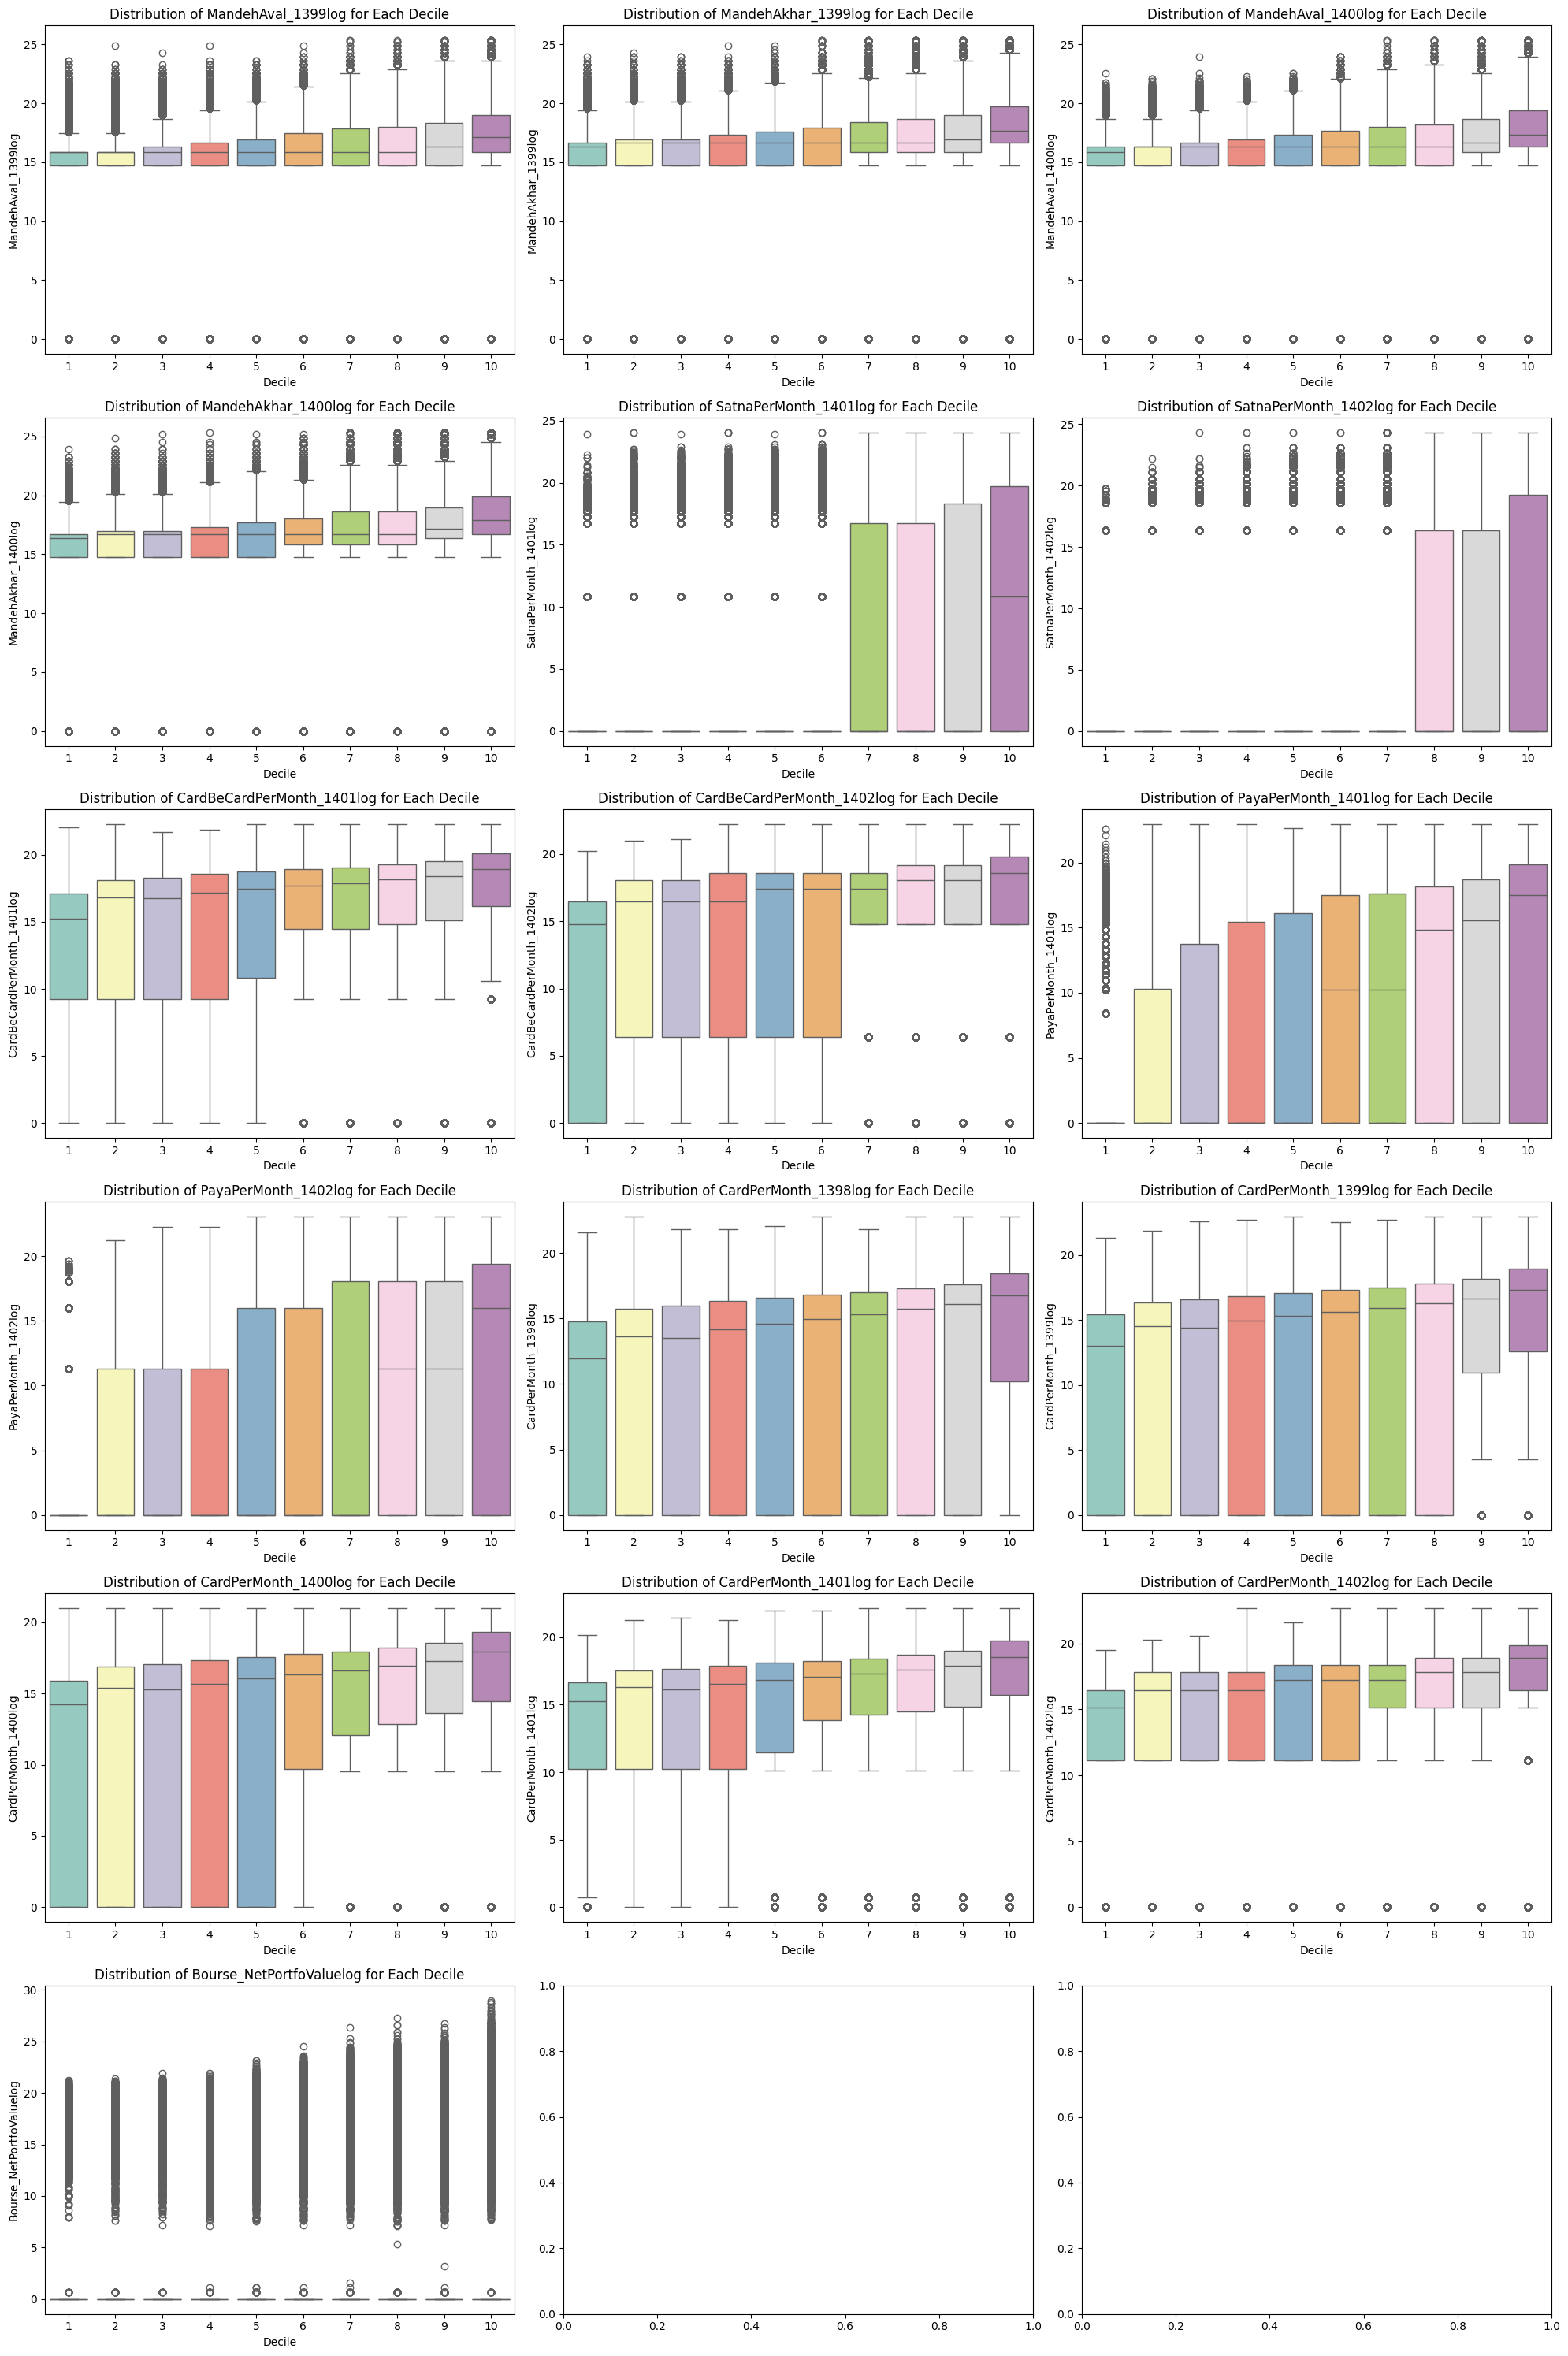

In [ ]:
fig, axes = plt.subplots(6, 3, figsize=(20, 30), sharey=False)

sns.boxplot(data=df, x='Decile', y='MandehAval_1399log', palette='Set3', ax=axes[0, 0])
axes[0, 0].set_title('Distribution of MandehAval_1399log for Each Decile')
axes[0, 0].set_ylabel('MandehAval_1399log')
sns.boxplot(x='Decile', y='MandehAkhar_1399log', data=df, palette='Set3', ax=axes[0, 1])
axes[0, 1].set_title('Distribution of MandehAkhar_1399log for Each Decile')
axes[0,1].set_ylabel('MandehAkhar_1399log')
sns.boxplot(data=df, x='Decile', y='MandehAval_1400log', palette='Set3', ax=axes[0, 2])
axes[0, 2].set_title('Distribution of MandehAval_1400log for Each Decile')
axes[0, 2].set_ylabel('MandehAval_1400log')
sns.boxplot(data=df, x='Decile', y='MandehAkhar_1400log', palette='Set3', ax=axes[1,0])
axes[1, 0].set_title('Distribution of MandehAkhar_1400log for Each Decile')
axes[1, 0].set_ylabel('MandehAkhar_1400log')


sns.boxplot(data=df, x='Decile', y='SatnaPerMonth_1401log', palette='Set3', ax=axes[1, 1])
axes[1, 1].set_title('Distribution of SatnaPerMonth_1401log for Each Decile')
axes[1, 1].set_ylabel('SatnaPerMonth_1401log')
sns.boxplot(data=df, x='Decile', y='SatnaPerMonth_1402log', palette='Set3', ax=axes[1, 2])
axes[1, 2].set_title('Distribution of SatnaPerMonth_1402log for Each Decile')
axes[1, 2].set_ylabel('SatnaPerMonth_1402log')



sns.boxplot(data=df, x='Decile', y='CardBeCardPerMonth_1401log', palette='Set3', ax=axes[2, 0])
axes[2, 0].set_title('Distribution of CardBeCardPerMonth_1401log for Each Decile')
axes[2, 0].set_ylabel('CardBeCardPerMonth_1401log')
sns.boxplot(data=df, x='Decile', y='CardBeCardPerMonth_1402log', palette='Set3', ax=axes[2, 1])
axes[2, 1].set_title('Distribution of CardBeCardPerMonth_1402log for Each Decile')
axes[2, 1].set_ylabel('CardBeCardPerMonth_1402log')

sns.boxplot(data=df, x='Decile', y='PayaPerMonth_1401log', palette='Set3', ax=axes[2, 2])
axes[2, 2].set_title('Distribution of PayaPerMonth_1401log for Each Decile')
axes[2, 2].set_ylabel('PayaPerMonth_1401log')
sns.boxplot(data=df, x='Decile', y='PayaPerMonth_1402log', palette='Set3', ax=axes[3, 0])
axes[3, 0].set_title('Distribution of PayaPerMonth_1402log for Each Decile')
axes[3, 0].set_ylabel('PayaPerMonth_1402log')


sns.boxplot(data=df, x='Decile', y='CardPerMonth_1398log', palette='Set3', ax=axes[3, 1])
axes[3, 1].set_title('Distribution of CardPerMonth_1398log for Each Decile')
axes[3, 1].set_ylabel('CardPerMonth_1398log')
sns.boxplot(data=df, x='Decile', y='CardPerMonth_1399log', palette='Set3', ax=axes[3, 2])
axes[3, 2].set_title('Distribution of CardPerMonth_1399log for Each Decile')
axes[3, 2].set_ylabel('CardPerMonth_1399log')
sns.boxplot(data=df, x='Decile', y='CardPerMonth_1400log', palette='Set3', ax=axes[4, 0])
axes[4, 0].set_title('Distribution of CardPerMonth_1400log for Each Decile')
axes[4, 0].set_ylabel('CardPerMonth_1400log')
sns.boxplot(data=df, x='Decile', y='CardPerMonth_1401log', palette='Set3', ax=axes[4,1])
axes[4, 1].set_title('Distribution of CardPerMonth_1401log for Each Decile')
axes[4, 1].set_ylabel('CardPerMonth_1401log')
sns.boxplot(data=df, x='Decile', y='CardPerMonth_1402log', palette='Set3', ax=axes[4,2])
axes[4, 2].set_title('Distribution of CardPerMonth_1402log for Each Decile')
axes[4, 2].set_ylabel('CardPerMonth_1402log')



sns.boxplot(data=df, x='Decile', y='Bourse_NetPortfoValuelog', palette='Set3', ax=axes[5, 0])
axes[5, 0].set_title('Distribution of Bourse_NetPortfoValuelog for Each Decile')
axes[5, 0].set_ylabel('Bourse_NetPortfoValuelog')


# for ax in axes[0:, :]:
#     ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')



fig.tight_layout()
plt.show()


In all the charts above, it can be observed that higher percentiles have more transactions such as card-to-card transfers, and their average and median values are higher.

,Has_SoeTaghzie,ISBimarKhas,IsMalool,Total
Decile,,,,
1,546.0,1532.0,8185.0,10263.0
2,525.0,1968.0,6840.0,9333.0
3,440.0,1142.0,2765.0,4347.0
4,344.0,1173.0,2376.0,3893.0
5,259.0,1324.0,2158.0,3741.0
6,221.0,1436.0,1905.0,3562.0
7,187.0,1294.0,1389.0,2870.0
8,138.0,1257.0,1163.0,2558.0
9,112.0,1203.0,1012.0,2327.0


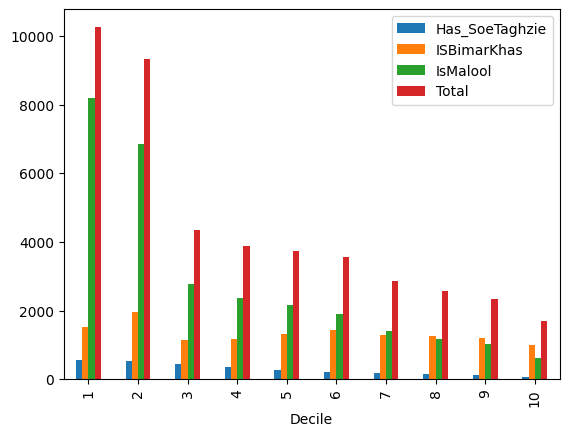

In [ ]:
'''
'ISBimarKhas'
'IsMalool'
'Has_SoeTaghzie'
'''
# Distribution of individuals in need of support based on different percentiles.

pv_hemayat=df.pivot_table(index='Decile',
                          values=['ISBimarKhas','IsMalool','Has_SoeTaghzie'],
                          aggfunc='sum')
pv_hemayat['Total']=pv_hemayat.aggregate('sum',axis=1)
pv_hemayat.plot(kind='bar')
pv_hemayat

,IsBehzisti_AfzayeshMostamari,IsKomite_AfzayeshMostamari,IsKomite_AfzayeshMostamariSayer,Total
Decile,,,,
1,11856.0,46860.0,3262.0,61978.0
2,10353.0,22604.0,3334.0,36291.0
3,3792.0,6172.0,1219.0,11183.0
4,3210.0,4334.0,932.0,8476.0
5,2604.0,2914.0,741.0,6259.0
6,1968.0,2295.0,562.0,4825.0
7,1553.0,1167.0,370.0,3090.0
8,1206.0,883.0,308.0,2397.0
9,1004.0,489.0,221.0,1714.0


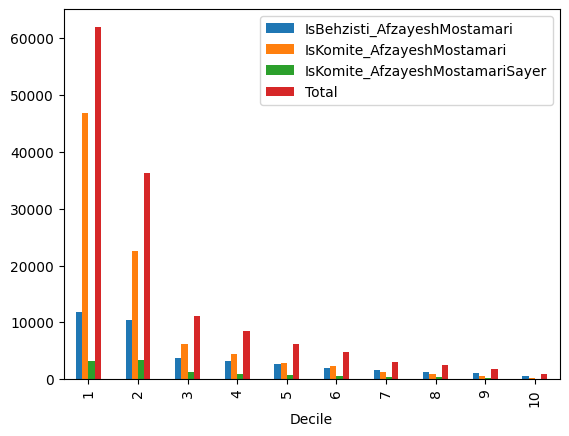

In [ ]:
'''
'IsBehzisti_AfzayeshMostamari'
'IsKomite_AfzayeshMostamari'
'IsKomite_AfzayeshMostamariSayer'
'''
# Distribution of individuals covered by support organizations based on different percentiles.


pv_hemayat=df.pivot_table(index='Decile',
                          values=['IsKomite_AfzayeshMostamariSayer','IsKomite_AfzayeshMostamari','IsBehzisti_AfzayeshMostamari' ],
                          aggfunc='sum')

pv_hemayat['Total']=pv_hemayat.aggregate('sum',axis=1)

pv_hemayat.plot(kind='bar')
pv_hemayat

We observe that there are individuals in higher percentiles who still receive support from welfare organizations and similar services.



,HasMojavezSenfi,Has_Saham_Edalat,ISKarmanddolat_1402
Decile,,,
1,983,100889.0,712
2,2024,98688.0,2838
3,2183,91313.0,3423
4,2902,91821.0,5006
5,3537,90775.0,6521
6,4208,90106.0,8181
7,5175,87684.0,9656
8,6494,84858.0,11263
9,8371,80618.0,11452


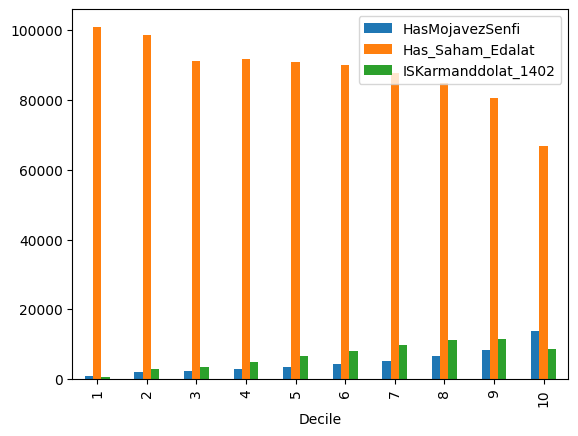

In [ ]:
pt = pd.pivot_table(data=df,
                    index=["Decile"],
                    values=["Has_Saham_Edalat","HasMojavezSenfi","ISKarmanddolat_1402" ],
                    aggfunc='sum',
                    )
pt.plot(kind="bar")

pt

Individuals who are government employees or have professional licenses tend to have better financial status.



Based on the chart below, if an individual has low income, they may fall into a higher percentile, whereas if a person has high income, they are unlikely to be in a lower percentile. This indicates that income is one (and not the only) determining feature of the welfare percentile in the dataset.

Text(0.5, 0, 'Daramad')

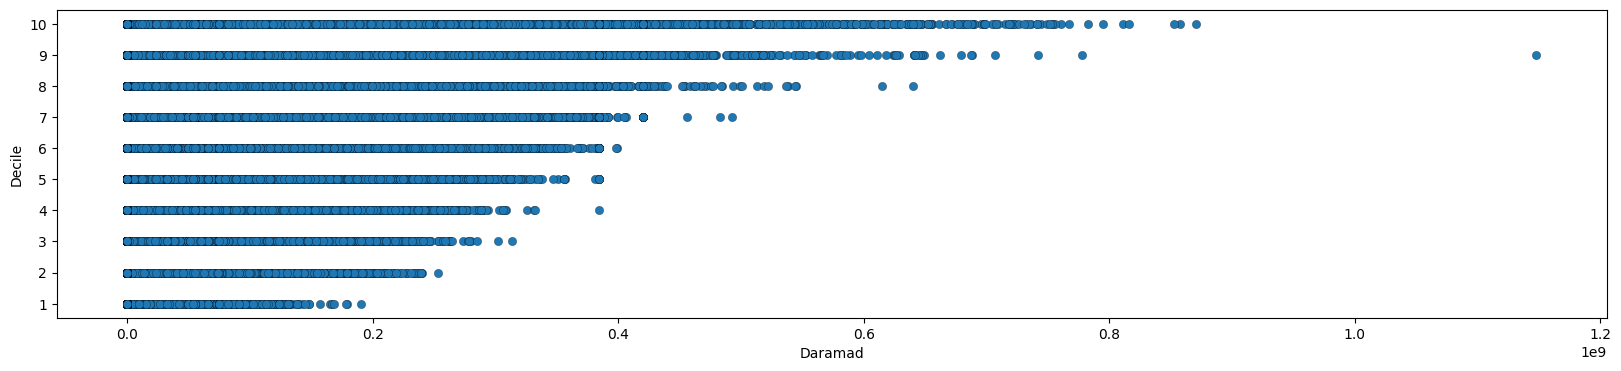

In [ ]:
plt.figure(figsize=(20,4))
plt.scatter(df['Daramad'],
            df['Decile'],
            edgecolors='black',
            marker='o',
            linewidths=0.2
            )

plt.yticks(np.arange(1,11,1))
plt.ylabel('Decile')
plt.xlabel('Daramad')

-------------------------